# MIL-STD-188-110C serial tone, block by block

This notebook follows one message through the modem: Figure 2 of the standard on the
transmit side, then an HF channel, then the receiver. Every step calls the same code that
`m110c-tx`, `m110c-chan` and `m110c-rx` use, so what is plotted is what the tools do.

It is generated from `docs/walkthrough.py` (`python tools/build_notebook.py`), and that
script is run by the test suite, so the two cannot drift apart. Paragraph numbers refer to
MIL-STD-188-110C; "INT-nnn" to the interpretations in `docs/SPEC_NOTES.md`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from m110c import fec, scrambler, symbols
from m110c.bits import bits_to_bytes, bytes_to_bits
from m110c.channel.watterson import ChannelSpec, WattersonChannel
from m110c.interleave import permutation
from m110c.modulate import modulate, rrc_taps
from m110c.rx.acquire import PreambleSearch
from m110c.rx.decode import DataDecoder
from m110c.rx.eom import EomDetector
from m110c.rx.equalize import EqualizingDemodulator
from m110c.spec import mode
from m110c.tx import transmit_bytes

plt.rcParams["figure.figsize"] = (8, 3)
MODE = mode(2400, "short")  # 2400 bps, 0.6-s interleaver
MESSAGE = b"THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG 0123456789\r\n" * 4
print(MODE, "-", len(MESSAGE), "bytes")

2400S - 224 bytes


## 1. Bytes to bits

The standard carries a synchronous bit stream (§4.2.3). Bytes go least significant bit
first, the UART convention, which the real recordings confirmed (INT-016). With
`--async 8N1` each byte also gets a start and a stop bit (INT-025).

In [2]:
user_bits = bytes_to_bits(MESSAGE)
print("'T' = 0x54 ->", user_bits[:8])

'T' = 0x54 -> [0 0 1 0 1 0 1 0]


## 2. Forward error correction (§5.3.2.3.3)

A rate-1/2, constraint-length-7 convolutional code: each input bit gives two coded bits
from two generator polynomials (T1 = x⁶+x⁴+x³+x+1, T2 = x⁶+x⁵+x⁴+x³+1). At 150 and 300 bps
the coded pairs are then repeated (INT-008). The receiver undoes this with a soft-decision
Viterbi decoder.

In [3]:
coded = fec.ConvolutionalEncoder().encode(user_bits)
print(len(user_bits), "bits ->", len(coded), "coded bits; first 16:", coded[:16])

1792 bits -> 3584 coded bits; first 16: [0 0 0 0 1 1 0 1 0 0 1 0 0 0 0 0]


## 3. Interleaving (§5.3.2.3.4)

A block interleaver spreads each burst of channel errors over many code words. Bits are
loaded down the rows of a matrix, stepping the row by 9 (by 7 at 75 bps, INT-007), and
fetched along diagonals. The plot shows where each input bit of one block ends up: a
fade that wipes out neighbouring channel bits hits bits far apart in the code.

block: 40 x 72 = 2880 bits


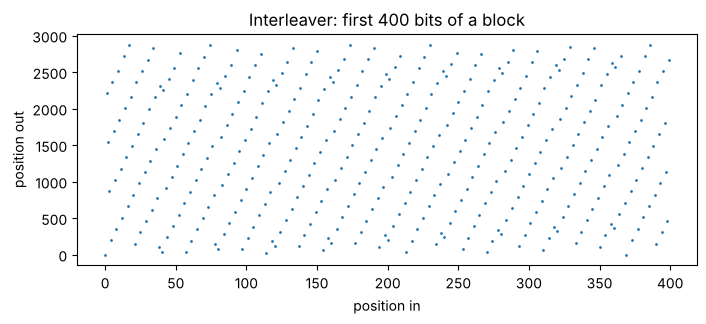

In [4]:
perm = permutation(MODE)
print("block:", MODE.interleaver_rows, "x", MODE.interleaver_cols, "=", perm.size, "bits")
plt.plot(perm[:400], ".", markersize=2)
plt.xlabel("position in")
plt.ylabel("position out")
plt.title("Interleaver: first 400 bits of a block")
plt.show()

## 4. Symbol formation, scrambling and framing (§5.3.2.3.6–8)

At 2400 bps every three interleaved bits pick one of eight phases, through a modified
Gray code (MGD, INT-020). Data frames alternate 32 unknown (data) symbols with 16 known
probe symbols, which the receiver uses to measure the channel. A pseudo-random sequence
then scrambles every symbol (Figure 6, INT-003), so even a run of zeros spreads over all
eight phases.

preamble 1440 symbols ( 0.6 s ), data phase 2880 symbols


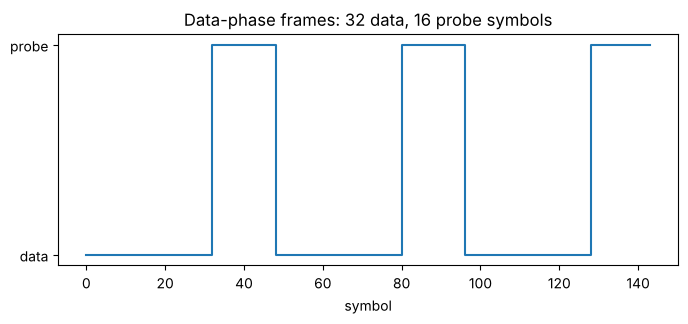

In [5]:
tx = transmit_bytes(MESSAGE, MODE)  # the whole chain, as m110c-tx runs it
n_pre = symbols.preamble_tribits(MODE).size
print("preamble", n_pre, "symbols (", n_pre / 2400, "s ), data phase", tx.size - n_pre, "symbols")
frame = np.r_[np.zeros(MODE.unknown_per_frame), np.ones(MODE.known_per_frame)]
plt.step(np.arange(3 * frame.size), np.tile(frame, 3), where="post")
plt.yticks([0, 1], ["data", "probe"])
plt.xlabel("symbol")
plt.title("Data-phase frames: 32 data, 16 probe symbols")
plt.show()

## 5. The preamble (§5.3.2.3.7.2)

The transmission starts with 3 (short or zero interleave) or 24 (long) segments of 15
channel symbols, each sent as 32 scrambled tribits. Nine fixed symbols open every segment,
then D1 and D2 (the mode, Table XI) and a count of segments remaining (INT-001). The
receiver uses them to find the signal, its carrier and timing, and the mode.

In [6]:
print("one segment's channel symbols:", symbols.preamble_channel_symbols(MODE)[:15])
print("D1, D2 =", MODE.d1_d2, "; count digits for 2 segments left:", symbols.count_symbols(2))

one segment's channel symbols: [0 1 3 0 1 3 1 2 0 6 4 4 4 6 0]
D1, D2 = (6, 4) ; count digits for 2 segments left: (4, 4, 6)


## 6. Modulation (§5.3.2.3.9)

Each tribit k is the phasor e^(jπk/4) (INT-021), shaped by a root-raised-cosine filter
(α = 0.25, INT-015) and moved to the 1800-Hz carrier. The output is complex baseband at
9600 samples/s whose real part is the audio. The spectrum fills 300–3300 Hz.

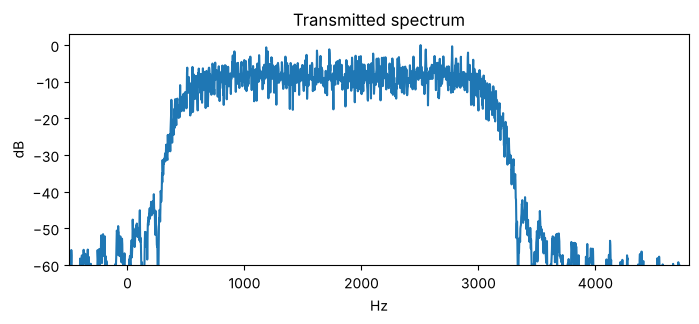

RRC filter taps at 4 samples/symbol: 65


In [7]:
x = modulate(tx)
f = np.fft.fftshift(np.fft.fftfreq(4096, 1 / 9600))
segments = x[: x.size // 4096 * 4096].reshape(-1, 4096) * np.hanning(4096)
psd = np.fft.fftshift(np.mean(np.abs(np.fft.fft(segments, axis=1)) ** 2, axis=0))
plt.plot(f, 10 * np.log10(psd / psd.max()))
plt.xlim(-500, 4800)
plt.ylim(-60, 3)
plt.xlabel("Hz")
plt.ylabel("dB")
plt.title("Transmitted spectrum")
plt.show()
print("RRC filter taps at 4 samples/symbol:", rrc_taps(4).size)

## 7. An HF channel (Appendix E)

The Watterson model: two paths 2 ms apart, each fading with a 1-Hz Gaussian Doppler
spectrum, plus noise at 18 dB in 3 kHz. That is one row of Table XVI, the conditions the
standard requires 2400 bps to survive with a bit error rate of at most 1e-5.

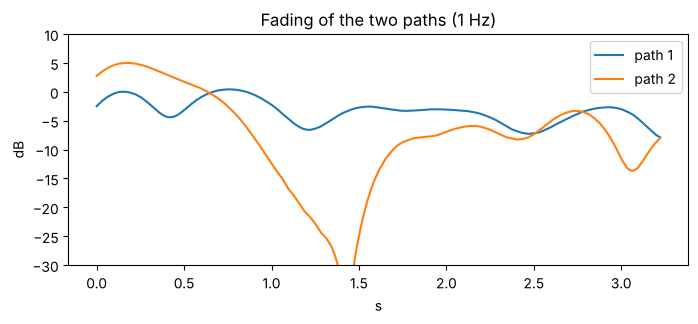

In [8]:
lead = np.zeros(4000, complex)
x_in = np.concatenate([lead, x, np.zeros(9600, complex)])
channel = WattersonChannel(ChannelSpec(2, 2.0, 1.0, 18.0), seed=7)
y = channel.process(x_in)
t = np.arange(x_in.size) / 9600
# The same seed gives the same fading; read it from a noiseless twin of the channel.
gains = WattersonChannel(ChannelSpec(2, 2.0, 1.0, None), seed=7)
g0, g1 = gains._fading[0].next(x_in.size), gains._fading[1].next(x_in.size)
plt.plot(t, 20 * np.log10(np.abs(g0) + 1e-9), label="path 1")
plt.plot(t, 20 * np.log10(np.abs(g1) + 1e-9), label="path 2")
plt.ylim(-30, 10)
plt.xlabel("s")
plt.ylabel("dB")
plt.legend()
plt.title("Fading of the two paths (1 Hz)")
plt.show()

## 8. Finding the preamble

The receiver searches ±400 Hz around 1800 Hz for the nine fixed slots of a preamble
segment, then reads D1, D2 and the count, and checks the count against the next segments
(§5.3.2.3.7.2, INT-001). Here it finds the first segment, with the carrier offset and the
mode.

In [9]:
search = PreambleSearch()
detection = search.process(y) or search.flush()
print(
    detection.mode,
    "at",
    round(detection.segment_start / 9600, 3),
    "s;",
    "carrier",
    round(detection.carrier_hz, 2),
    "Hz; segments left",
    detection.count,
)

2400S at 0.419 s; carrier 1800.16 Hz; segments left 2


## 9. Equalisation

At every probe the receiver estimates the channel (both paths, with their fading), and
computes a decision-feedback equaliser from it. The plot shows the received symbols
before and after: the raw samples are smeared by multipath and fading; the equalised
ones sit on the eight phases. (Shown after descrambling, so they are the MGD symbols.)

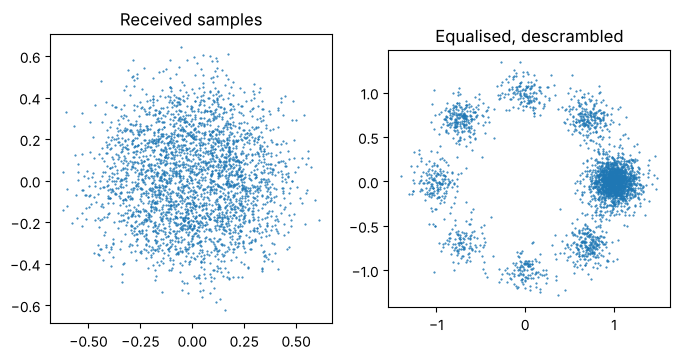

In [10]:
start = int(detection.segment_start) - 8
demod = EqualizingDemodulator(detection.mode, detection, start_index=start)
z, var = demod.process(y[start:])
z2, var2 = demod.finish()
z, var = np.concatenate([z, z2]), np.concatenate([var, var2])
n_data = tx.size - symbols.preamble_tribits(MODE).size  # what followed is noise, not data
z, var = z[:n_data], var[:n_data]
clean = z * np.conj(np.exp(1j * np.pi / 4 * scrambler.data_sequence(0, z.size)))
raw = y[start + 4 * symbols.preamble_tribits(MODE).size :][::4][: z.size]
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].plot(raw.real, raw.imag, ".", markersize=1)
ax[0].set_title("Received samples")
ax[1].plot(clean.real, clean.imag, ".", markersize=1)
ax[1].set_title("Equalised, descrambled")
for a in ax:
    a.set_aspect("equal")
plt.show()

## 10. Decoding

The equalised symbols go back through the chain in reverse: descramble, soft-demap (each
symbol's bits get a reliability, weighted by the equaliser's error variance), deinterleave,
Viterbi-decode. The end-of-message pattern (§5.3.2.3.1, INT-018) says where the user data
stopped.

In [11]:
decoder, eom = DataDecoder(detection.mode), EomDetector()
bits = eom.process(decoder.process(z, var))
bits = np.concatenate([bits, eom.process(decoder.finish()), eom.finish()])
received = bits_to_bytes(bits[: bits.size // 8 * 8])
print("EOM found:", eom.found, "; SNR on the probes:", round(decoder.snr_db, 1), "dB")
print("bytes:", len(received), "; identical to the message:", received == MESSAGE)
print(received[:58].decode())

EOM found: True ; SNR on the probes: 14.0 dB
bytes: 224 ; identical to the message: True
THE QUICK BROWN FOX JUMPS OVER THE LAZY DOG 0123456789
TH


## Where to go next

- `docs/CONFORMANCE.md`: every Table XVI row, run for a million bits.
- `docs/PERFORMANCE.md`: how the receiver was designed and measured, including what did
  not work.
- `docs/SPEC_NOTES.md`: every place where the standard is ambiguous, and what we chose.
- `docs/VALIDATION.md`: the comparison with recordings of real modems.